In [3]:
import numpy as np
import pandas as pd

In [4]:
fname_data = "../data/CM/Natural_CM.csv"
fname_gen = "../data/CM/Generated_CM.csv"

df_data = pd.read_csv(fname_data)
df_gen = pd.read_csv(fname_gen)

## Logistic regression

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from adabmDCA.fasta import encode_sequence, get_tokens

tokens = get_tokens("protein")
X_train = np.eye(21)[encode_sequence(df_data["sequence"].values, tokens=tokens)].reshape(len(df_data), -1)
y_train = df_data["label"].values
X_test = np.eye(21)[encode_sequence(df_gen["sequence"].values, tokens=tokens)].reshape(len(df_gen), -1)
y_test = df_gen["label"].values

logreg = LogisticRegression(max_iter=1000)
logreg.fit(X_train, y_train)

y_pred = logreg.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy on generated data: {accuracy * 100:.2f}%")

Accuracy on generated data: 78.36%


## Analyze the RBM model

In [54]:
import torch
from annadca import annaRBMcat
from annadca.dataset import annaDataset
from annadca.utils import get_eigenvalues_history
from annadca.plot import plot_PCA
from adabmDCA.fasta import get_tokens
from adabmDCA.stats import get_freq_single_point, get_freq_two_points, get_correlation_two_points
from adabmDCA.fasta import decode_sequence, encode_sequence


fname_data = "../data/CM/Natural_CM.csv"
fname_gen = "../data/CM/Generated_CM.csv"
fname_model = "../models/CM_H1000_lr0.001_params.h5"
fname_chains = "../models/CM_H1000_lr0.001_chains.fasta"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
dtype = torch.float32

# Import dataset
tokens = get_tokens("protein")
dataset = annaDataset(
    path_data=fname_data,
    column_names="header",
    column_sequences="sequence",
    column_labels="label",
    alphabet=tokens,
    device=device,
    dtype=dtype,
)

dataset_test = annaDataset(
    path_data=fname_gen,
    column_names="header",
    column_sequences="sequence",
    column_labels="label",
    alphabet=tokens,
    device=device,
    dtype=dtype,
)

data = dataset.data_one_hot
weights = dataset.weights.view(-1)
labels_data = dataset.to_label(dataset.labels_one_hot)

# Load the chains
rbm = annaRBMcat()
rbm.load(fname_model, device=device, dtype=dtype)
chains = rbm.load_chains(filename=fname_chains, alphabet=tokens, device=device, dtype=dtype)
labels_chains = dataset.to_label(chains["label"])

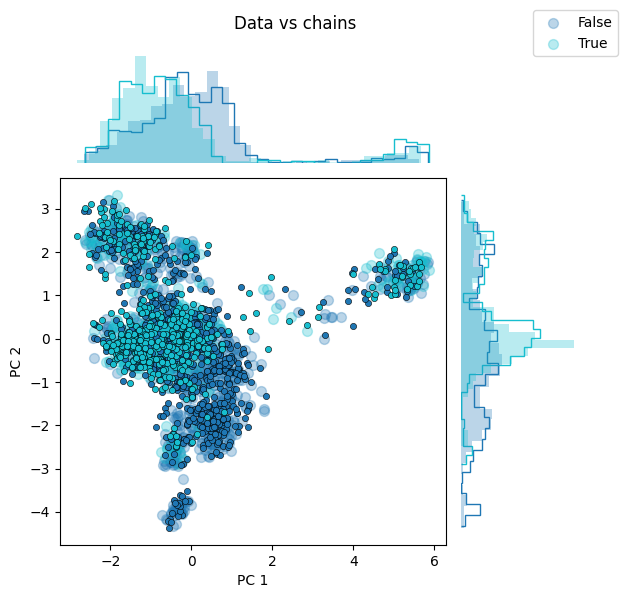

In [7]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Project data and chains on the same PCA space
pca = PCA(n_components=2)
data_proj = pca.fit_transform(data.reshape(len(data), -1).cpu().numpy())
chains_proj = pca.transform(chains["visible"].view(len(chains["visible"]), -1).cpu().numpy())

# Define the colors
unique_labels = np.unique(labels_data)
cmap = plt.get_cmap("tab10", len(unique_labels))
label_to_color = {label.item(): cmap(i) for i, label in enumerate(unique_labels)}

fig = plt.figure(figsize=(6,6))
fig = plot_PCA(
    fig=fig,
    data1=data_proj,
    labels1=labels_data,
    data2=chains_proj,
    labels2=labels_chains,
    label_to_color=label_to_color,
    dim1=0,
    dim2=1,
    title="Data vs chains",
    split_labels=True,
)
fig.legend(bbox_to_anchor=(1.05, 1.0))
fig.tight_layout()

### Sample unconditioned

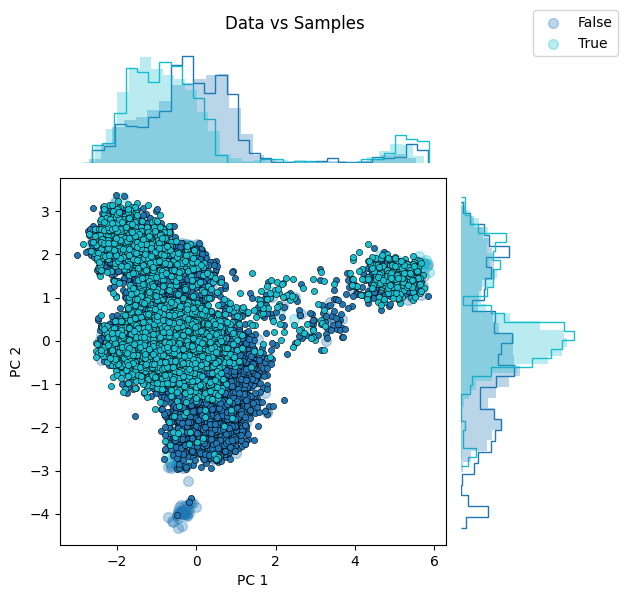

In [6]:
samples = rbm.sample(gibbs_steps=10000, num_samples=10000)
samples_proj = pca.transform(samples["visible"].view(len(samples["visible"]), -1).cpu().numpy())
samples_labels = dataset.to_label(samples["label"])

fig = plt.figure(figsize=(6,6))
fig = plot_PCA(
    fig=fig,
    data1=data_proj,
    labels1=labels_data,
    data2=samples_proj,
    labels2=samples_labels,
    label_to_color=label_to_color,
    dim1=0,
    dim2=1,
    title="Data vs Samples",
    split_labels=True,
)
fig.legend(bbox_to_anchor=(1.05, 1.0))
fig.tight_layout()

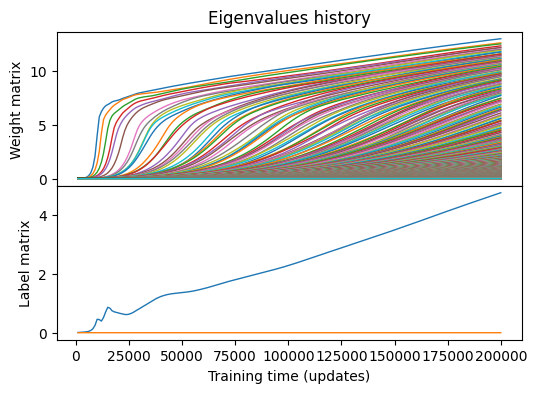

In [7]:
updates, eigenvalues = get_eigenvalues_history(fname_model, target_matrix="weight_matrix", device=device, dtype=dtype)
updates, eigenvalues_labels = get_eigenvalues_history(fname_model, target_matrix="label_matrix", device=device, dtype=dtype)

# Plot the eigenvalues history. first row is the weight matrix, second row is the label matrix.
fig, ax = plt.subplots(2, 1, figsize=(6, 4), sharex=True, gridspec_kw={'hspace': 0})
ax[0].plot(updates, eigenvalues, lw=1)
ax[1].plot(updates, eigenvalues_labels, lw=1)
ax[1].set_xlabel("Training time (updates)")
ax[0].set_ylabel("Weight matrix")
ax[1].set_ylabel("Label matrix")
ax[0].set_title("Eigenvalues history");

### Conditioned Sampling

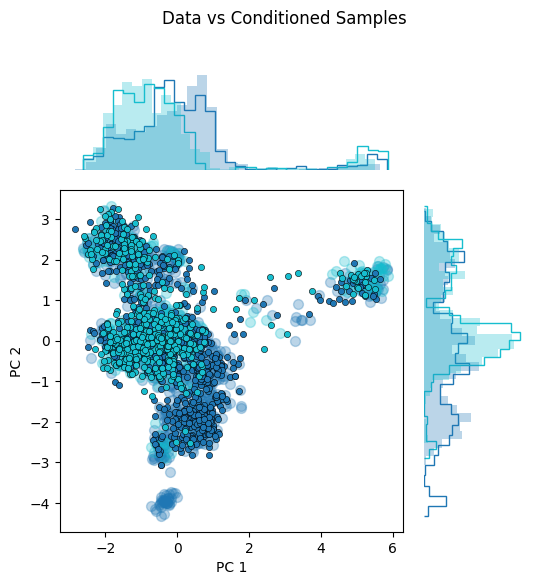

In [8]:
rbm.load(fname_model, device=device, dtype=dtype)
cond_chains = rbm.sample_conditioned(
    gibbs_steps=100000,
    targets=dataset.labels_one_hot,
)

cond_chains_proj = pca.transform(cond_chains["visible"].view(len(cond_chains["visible"]), -1).cpu().numpy())
cond_chains_labels = labels_data

fig = plt.figure(figsize=(6,6))
fig = plot_PCA(
    fig=fig,
    data1=data_proj,
    labels1=labels_data,
    data2=cond_chains_proj,
    labels2=cond_chains_labels,
    label_to_color=label_to_color,
    dim1=0,
    dim2=1,
    title="Data vs Conditioned Samples",
    split_labels=True,
)

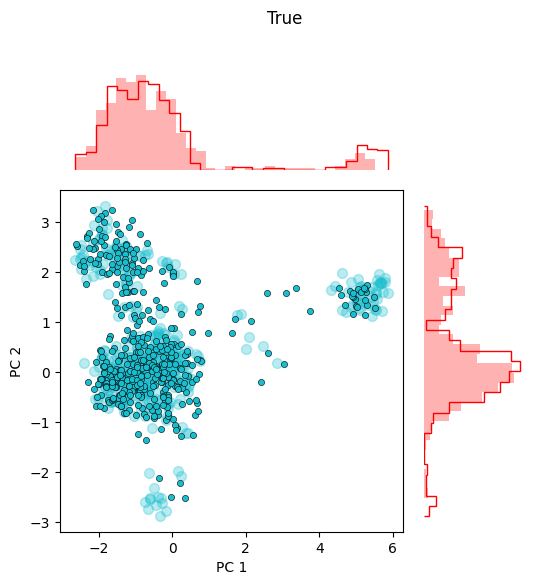

In [9]:
# Plot pca of conditioned chains and data but only one label
label_idx = 1
label = dataset.idx_to_label[label_idx]
mask_data = labels_data == label
mask_gen = cond_chains_labels == label
data_proj_label = data_proj[mask_data]
chains_proj_label = cond_chains_proj[mask_gen]

fig = plt.figure(figsize=(6,6))
fig = plot_PCA(
    fig=fig,
    data1=data_proj_label,
    labels1=labels_data[mask_data],
    data2=chains_proj_label,
    labels2=cond_chains_labels[mask_gen],
    label_to_color={label: cmap(label_idx)},
    dim1=0,
    dim2=1,
    title=label,
    split_labels=False,
)

In [10]:
# Train accuracy
predictions = rbm.predict_labels(visible=dataset.data_one_hot)
accuracy = (predictions.argmax(-1) == dataset.labels_one_hot.argmax(-1)).float().mean().item()
print(f"Train accuracy: {accuracy}")

predictions = rbm.predict_labels(visible=dataset_test.data_one_hot)
accuracy = (predictions.argmax(-1) == dataset_test.labels_one_hot.argmax(-1)).float().mean().item()
print(f"Test accuracy: {accuracy}")

Train accuracy: 0.9203540086746216
Test accuracy: 0.7966101765632629


In [ ]:
fi = get_freq_single_point(data=dataset.data_one_hot, weights=dataset.weights, pseudo_count=1e-8)
fij = get_freq_two_points(data=dataset.data_one_hot, weights=dataset.weights, pseudo_count=1e-8)
pi = get_freq_single_point(data=cond_chains["visible"], weights=None, pseudo_count=1e-8)
pij = get_freq_two_points(data=cond_chains["visible"], weights=None, pseudo_count=1e-8)

pearson, slope = get_correlation_two_points(fij, pij, fi, pi)
print(f"Pearson correlation: {pearson:.4f}, slope: {slope:.4f}")

Pearson correlation: 0.7986, slope: 0.7372


## Importance Sampling

In [69]:
from typing import Dict, Tuple

def importance_sampling(
    rbm: annaRBMcat,
    num_samples: int,
    wild_type: torch.Tensor,
    target_label_oh: torch.Tensor,
    ngibbs: int,
    is_strength: float,
    gen_strength: float = 1.0,
    label_strength: float = 1.0,
) -> Dict[str, torch.Tensor]:
    """Perform importance sampling with the RBM conditioned to a target label.

    Args:
        rbm (annaRBMbin): annaRBMbin instance.
        num_samples (int): Number of samples to generate.
        wild_type (torch.Tensor): Wild type sequence.
        target_label_oh (torch.Tensor): One-hot encoded target label.
        ngibbs (int): Number of Gibbs sampling steps.
        is_strength (float): Importance weight for the wild type.
        gen_strength (float, optional): Controls the relative importance of the generative Hamiltonian. Defaults to 1.0.
        label_strength (float, optional): Controls the relative importance of the label Hamiltonian. Defaults to 1.0.

    Returns:
        Dict[str, torch.Tensor]: Generated samples.
    """
    # replicate the wild type sequence
    samples = wild_type.unsqueeze(0).repeat(num_samples, 1, 1)
    
    # modify the visible bias for importance sampling
    rbm_mod = rbm.clone()

    # rescale the generative hamiltonian by gen_strength
    rbm_mod.params["weight_matrix"] *= gen_strength
    rbm_mod.params["vbias"] *= gen_strength
    rbm_mod.params["hbias"] *= gen_strength

    # bias on the wild type sites using importance sampling
    rbm_mod.params["vbias"] += is_strength * wild_type

    # rescale the label hamiltonian by label_strength
    rbm_mod.params["label_matrix"] *= label_strength
    rbm_mod.params["lbias"] *= label_strength

    # replicate the target label
    target_label_oh = target_label_oh.unsqueeze(0).repeat(num_samples, 1)
    samples = rbm_mod.sample_conditioned(
        gibbs_steps=ngibbs,
        visible=samples,
        targets=target_label_oh
    )
    
    return samples


def get_energy_contributions(
    rbm: annaRBMcat,
    samples: Dict[str, torch.Tensor],
    target_label_oh: torch.Tensor,
) -> Tuple[torch.Tensor, torch.Tensor]:
    # Generative energy
    Hgen = rbm.compute_energy_visibles(
        visible=samples["visible"],
    )
    # Label probability
    target_label_idx = target_label_oh.argmax(dim=-1)
    p_label = rbm.predict_labels(**samples)[:, target_label_idx]
    return Hgen, p_label

def get_distance_from_wt(
    wt: torch.Tensor,
    samples: Dict[str, torch.Tensor]
) -> torch.Tensor:
    L = samples["visible"].size(1)
    distances = L - torch.all((samples["visible"] == wt.unsqueeze(0)), dim=-1).sum(-1)
    return distances

In [9]:
# True -> Functional true
# False -> Functional false
functional_false_mask = dataset.to_label(dataset.labels_one_hot) == False
functional_false_sequences = dataset.data_one_hot[functional_false_mask]
target_label_oh = dataset.labels_one_hot[~functional_false_mask][0]

idx_wt = 11
wild_type = dataset.data_one_hot[idx_wt]

# visualize the wild type sequence in the pca space
wt_pca = pca.transform(wild_type.view(1, -1).cpu().numpy())

plt.rcParams.update({'font.size': 14,
                     'text.usetex': True})

import plotly.express as px

df_plot = pd.DataFrame({
    "PCA1": data_proj[:, 0],
    "PCA2": -data_proj[:, 1],
    "Label": labels_data,
    "Index": np.arange(len(labels_data))
})


fig_plotly = px.scatter(
    df_plot,
    x="PCA1",
    y="PCA2",
    color="Label",
    hover_data=["Index", "PCA1", "PCA2"],
    title="Natural Sequences (Interactive)",
    width=600,
    height=600
)

# plot also the wild type in the same figure
df_wild_type = pd.DataFrame({
    "PCA1": wt_pca[:, 0],
    "PCA2": -wt_pca[:, 1],
    "Label": "wild type",
    "Index": [999999],
})
fig_plotly.add_scatter(
    x=df_wild_type["PCA1"],
    y=df_wild_type["PCA2"],
    mode="markers",
    marker=dict(size=16, color="green", symbol="x", line=dict(width=2, color="black")),
    name="Wild Type (False)",
)
fig_plotly.show()

In [10]:
def get_energy_logreg(samples, target_label_oh):
    idx_label = target_label_oh.argmax().item()
    betas = logreg.coef_[idx_label]
    Hdiscr = - samples["visible"].cpu().numpy() @ betas
    return Hdiscr

def get_prob_logreg(samples, target_label_oh):
    idx_label = target_label_oh.argmax().item()
    p_label = logreg.predict_proba(samples["visible"].cpu().numpy().reshape(len(samples["visible"]), -1))[:, idx_label]
    return p_label

### Calibration

Target wild-type indices: 783, 1074, 145, 365, 960

In [67]:
idx_wt = 145
wild_type = dataset.data_one_hot[idx_wt]

# visualize the wild type sequence in the pca space
wt_pca = pca.transform(wild_type.view(1, -1).cpu().numpy())

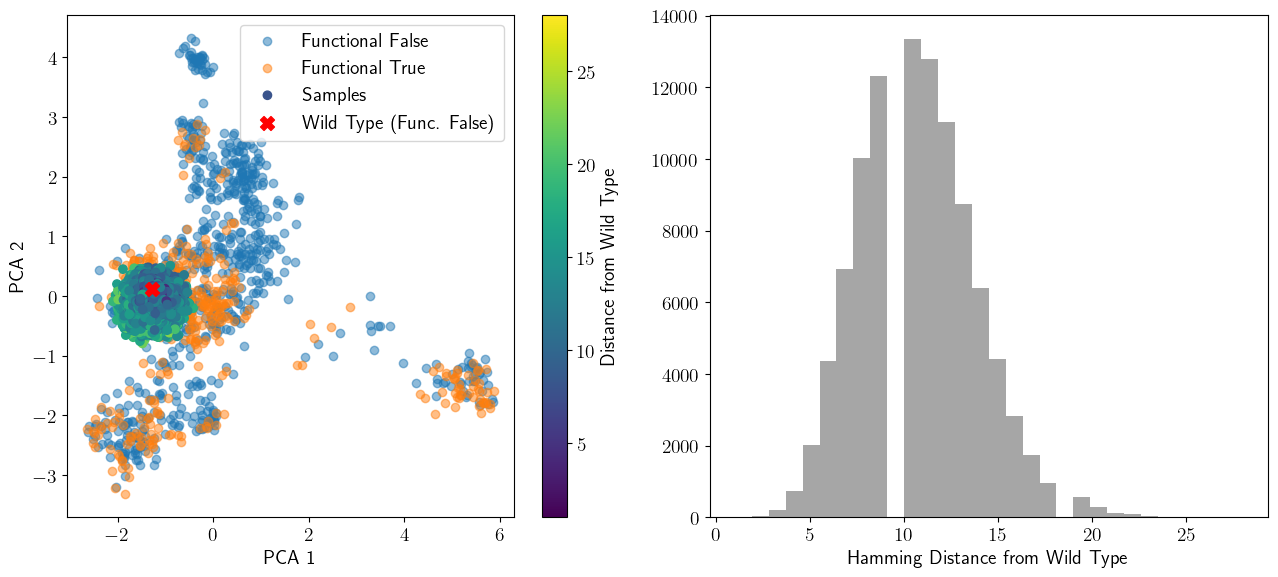

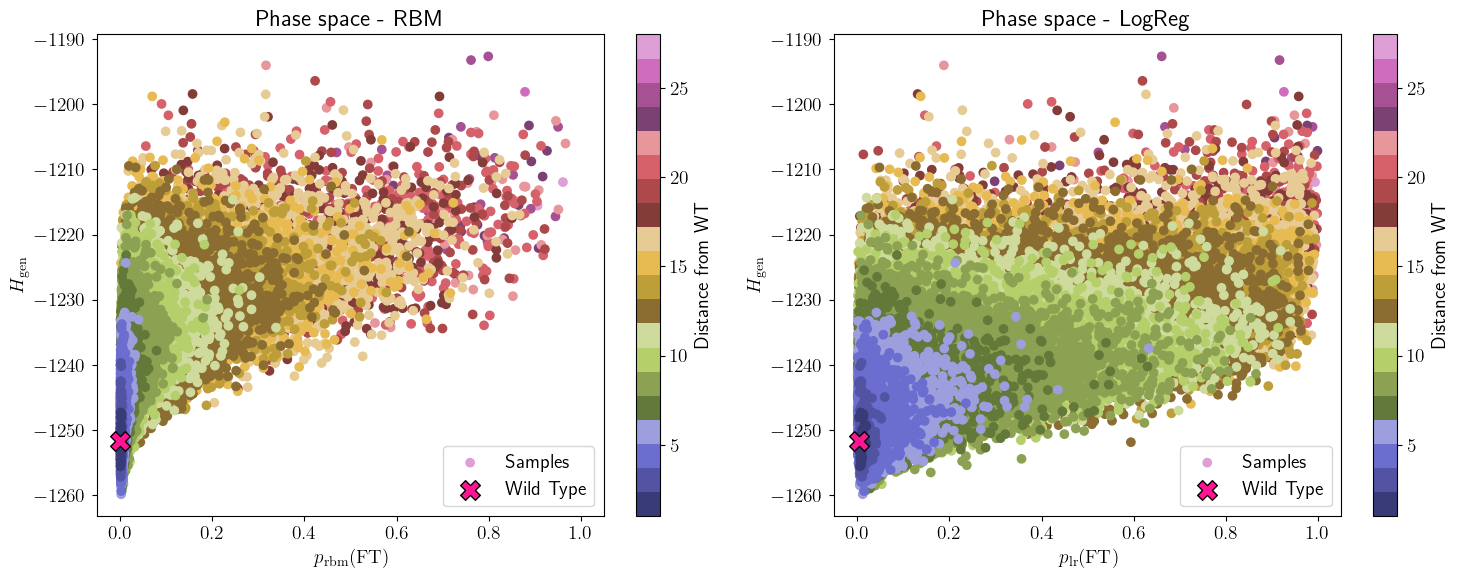

In [111]:
num_samples = 100000
ngibbs = 5000
is_strength = 2.2
gen_strength = 1.0
label_strength = 8.0

samples = importance_sampling(
    rbm=rbm,
    num_samples=num_samples,
    wild_type=wild_type,
    target_label_oh=target_label_oh,
    ngibbs=ngibbs,
    is_strength=is_strength,
    gen_strength=gen_strength,
    label_strength=label_strength,
)

samples_pca = pca.transform(samples["visible"].view(len(samples["visible"]), -1).cpu().numpy())
distances = get_distance_from_wt(
    wt=wild_type,
    samples=samples,
)

fig, ax = plt.subplots(1, 2, figsize=(13, 6), dpi=100)
ax[0].scatter(data_proj[functional_false_mask, 0], -data_proj[functional_false_mask, 1], label='Functional False', alpha=0.5)
ax[0].scatter(data_proj[~functional_false_mask, 0], -data_proj[~functional_false_mask, 1], label='Functional True', alpha=0.5)
sc = ax[0].scatter(samples_pca[:, 0], -samples_pca[:, 1], c=distances.cpu().numpy(), cmap='viridis', label='Samples')
ax[0].scatter(wt_pca[:, 0], -wt_pca[:, 1], marker="X", s=100, c='red', label='Wild Type (Func. False)')
ax[0].legend()
ax[0].set_xlabel("PCA 1")
ax[0].set_ylabel("PCA 2")
# colorbar
cbar = plt.colorbar(sc, ax=ax[0])
cbar.set_label(r"Distance from Wild Type")

ax[1].hist(distances.cpu().numpy(), bins=30, color='gray', alpha=0.7)
ax[1].set_xlabel("Hamming Distance from Wild Type")

fig.tight_layout();

Hgen, p_rbm = get_energy_contributions(
    rbm=rbm,
    samples=samples,
    target_label_oh=target_label_oh,
)
p_lr = get_prob_logreg(samples, target_label_oh)
Hgen_wt, p_rbm_wt = get_energy_contributions(
    rbm=rbm,
    samples={"visible": wild_type.unsqueeze(0)},
    target_label_oh=target_label_oh,
)

p_lr_wt = get_prob_logreg({"visible": wild_type.unsqueeze(0)}, target_label_oh)
fig, ax = plt.subplots(1, 2, figsize=(15, 6), dpi=100)

idx = np.argsort(distances.cpu().numpy())[::-1]
sc0 = ax[0].scatter(p_rbm.cpu().numpy()[idx], Hgen.cpu().numpy()[idx], c=distances.cpu().numpy()[idx], cmap="tab20b", label=f"Samples")
ax[0].set_ylabel(r"$H_{\mathrm{gen}}$")
ax[0].set_xlabel(r"$p_{\mathrm{rbm}}(\mathrm{FT})$")
ax[0].set_title(f"Phase space - RBM")
ax[0].scatter(p_rbm_wt.item(), Hgen_wt.item(), marker="X", s=200, c='deeppink', label='Wild Type', edgecolor='black')
ax[0].set_xlim(-0.05, 1.05)
ax[0].legend()

sc1 = ax[1].scatter(p_lr[idx], Hgen.cpu().numpy()[idx], c=distances.cpu().numpy()[idx], cmap="tab20b", label=f"Samples")
ax[1].set_ylabel(r"$H_{\mathrm{gen}}$")
ax[1].set_xlabel(r"$p_{\mathrm{lr}}(\mathrm{FT})$")
ax[1].set_title(f"Phase space - LogReg")
ax[1].scatter(p_lr_wt.item(), Hgen_wt.item(), marker="X", s=200, c='deeppink', label='Wild Type', edgecolor='black')
ax[1].set_xlim(-0.05, 1.05)
ax[1].legend()

cbar0 = plt.colorbar(sc0, ax=ax[0])
cbar0.set_label(r"Distance from WT")

cbar1 = plt.colorbar(sc1, ax=ax[1])
cbar1.set_label(r"Distance from WT")

fig.tight_layout()

In [112]:
from adabmDCA.fasta import write_fasta

headers = [f"gen_{i}" for i in range(num_samples)]
write_fasta(
    fname="../generated/CM/Seq_gen_RBM_gen_strength1.0_label_strength8.0_is_strength2.2.faa",
    headers=headers,
    sequences=samples["visible"].argmax(-1).cpu().numpy(),
    numeric_input=True,
)

Iterate the previous plot for many values of the importance weight

In [82]:
num_samples = 5000
ngibbs = 5000
gen_strength = 1.0
label_strength = 1.0

is_strength_list = 3 * np.append(np.array([0.]), np.logspace(-3, 0, 10))

fname = f"../generated/CM/CM_importance_sampling_WT{idx_wt}_gen_strength{gen_strength}_label_strength{label_strength}_ngibbs{ngibbs}.csv"
is_strength_records = []
p_rbm_records, p_lr_records, Hgen_records, distance_records, sample_records = [], [], [], [], []

for is_strength in is_strength_list:
    print(f"Importance weight: {is_strength:.4f}")
    samples = importance_sampling(
        rbm=rbm,
        num_samples=num_samples,
        wild_type=wild_type,
        target_label_oh=target_label_oh,
        ngibbs=ngibbs,
        is_strength=is_strength,
        gen_strength=gen_strength,
        label_strength=label_strength,
    )
    
    distances = get_distance_from_wt(
        wt=wild_type,
        samples=samples,
    )
    
    Hgen, p_rbm = get_energy_contributions(
        rbm=rbm,
        samples=samples,
        target_label_oh=target_label_oh,
    )
    p_lr = get_prob_logreg(samples, target_label_oh)
    
    # decode sequences
    samples_dec = list(decode_sequence(samples["visible"].argmax(dim=-1).tolist(), tokens=tokens))
    sample_records.extend(samples_dec)
    distance_records.extend(distances.tolist())
    Hgen_records.extend(Hgen.tolist())
    p_rbm_records.extend(p_rbm.tolist())
    p_lr_records.extend(p_lr.tolist())
    is_strength_records.extend([is_strength] * len(samples["visible"]))

# store results in a dataframe
df_results = pd.DataFrame({
    "Sample": sample_records,
    "Distance_from_WT": distance_records,
    "Hgen": Hgen_records,
    "p_rbm": p_rbm_records,
    "p_lr": p_lr_records,
    "Importance_strength": is_strength_records,
})
df_results.to_csv(fname, index=False)

Importance weight: 0.0000
Importance weight: 0.0030
Importance weight: 0.0065
Importance weight: 0.0139
Importance weight: 0.0300
Importance weight: 0.0646
Importance weight: 0.1392
Importance weight: 0.3000
Importance weight: 0.6463
Importance weight: 1.3925
Importance weight: 3.0000


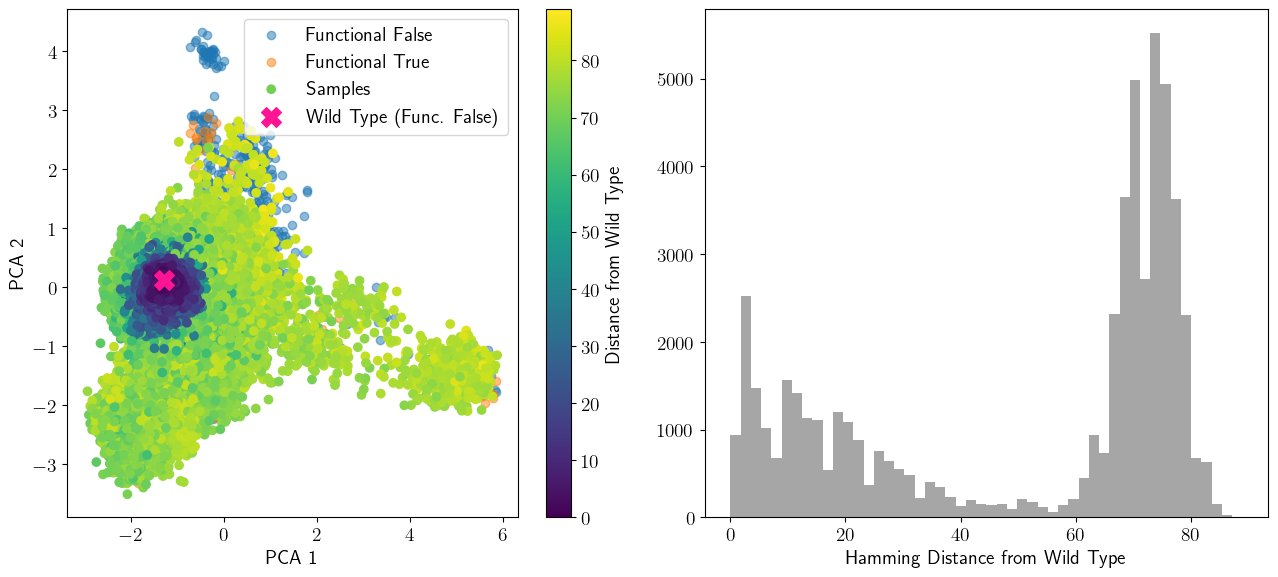

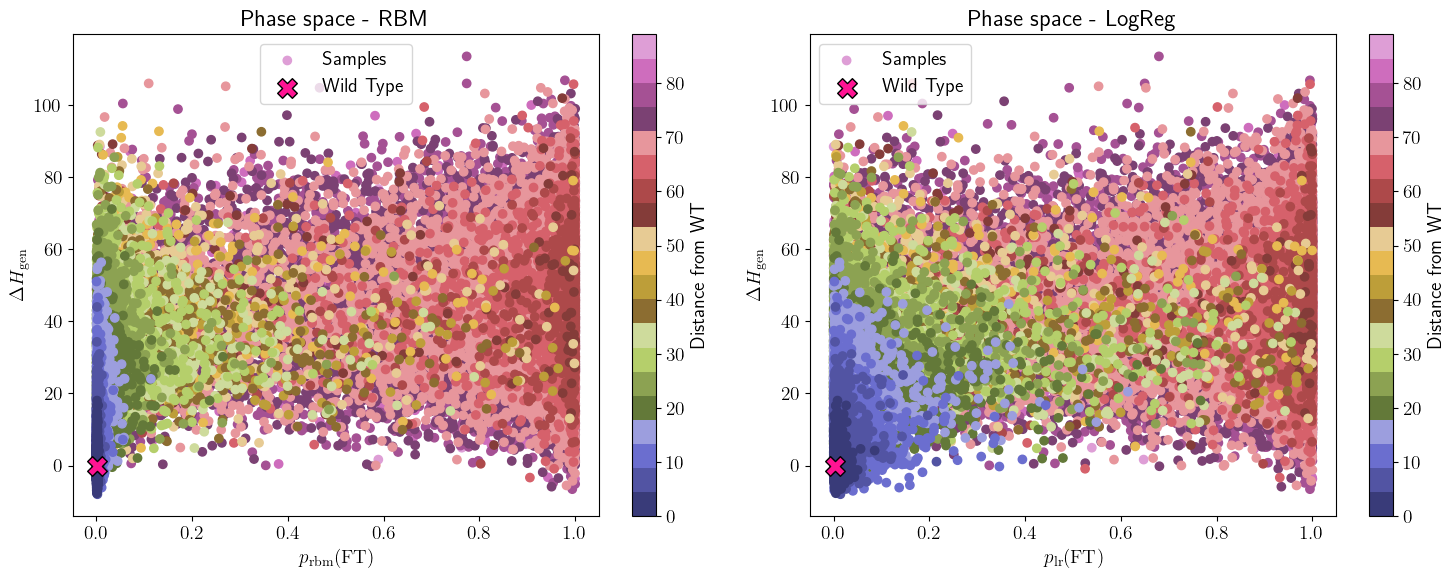

In [102]:
# import data from CSV
df_results = pd.read_csv(fname)

# pca of the samples
samples_enc = np.eye(len(tokens))[encode_sequence(df_results["Sample"].values, tokens=tokens)]
samples_pca = pca.transform(samples_enc.reshape(len(samples_enc), -1))


fig, ax = plt.subplots(1, 2, figsize=(13, 6), dpi=100)
ax[0].scatter(data_proj[functional_false_mask, 0], -data_proj[functional_false_mask, 1], label='Functional False', alpha=0.5)
ax[0].scatter(data_proj[~functional_false_mask, 0], -data_proj[~functional_false_mask, 1], label='Functional True', alpha=0.5)
sc = ax[0].scatter(samples_pca[:, 0], -samples_pca[:, 1], c=df_results["Distance_from_WT"].values, cmap='viridis', label='Samples')
ax[0].scatter(wt_pca[:, 0], -wt_pca[:, 1], marker="X", s=200, c='deeppink', label='Wild Type (Func. False)')
ax[0].legend()
ax[0].set_xlabel("PCA 1")
ax[0].set_ylabel("PCA 2")
# colorbar
cbar = plt.colorbar(sc, ax=ax[0])
cbar.set_label(r"Distance from Wild Type")

ax[1].hist(df_results["Distance_from_WT"].values, bins=50, color='gray', alpha=0.7)
ax[1].set_xlabel("Hamming Distance from Wild Type")

fig.tight_layout();

fig, ax = plt.subplots(1, 2, figsize=(15, 6), dpi=100)

idx = np.argsort(df_results["Distance_from_WT"].values)[::-1]
sc0 = ax[0].scatter(df_results["p_rbm"].values[idx], df_results["Hgen"] - Hgen_wt.item(), c=df_results["Distance_from_WT"].values[idx], cmap="tab20b", label=f"Samples")
ax[0].set_ylabel(r"$\Delta H_{\mathrm{gen}}$")
ax[0].set_xlabel(r"$p_{\mathrm{rbm}}(\mathrm{FT})$")
ax[0].set_title(f"Phase space - RBM")
ax[0].scatter(p_rbm_wt.item(), 0, marker="X", s=200, c='deeppink', label='Wild Type', edgecolor='black')
ax[0].set_xlim(-0.05, 1.05)
ax[0].legend()

sc1 = ax[1].scatter(df_results["p_lr"].values[idx], df_results["Hgen"] - Hgen_wt.item(), c=df_results["Distance_from_WT"].values[idx], cmap="tab20b", label=f"Samples")
ax[1].set_ylabel(r"$\Delta H_{\mathrm{gen}}$")
ax[1].set_xlabel(r"$p_{\mathrm{lr}}(\mathrm{FT})$")
ax[1].set_title(f"Phase space - LogReg")
ax[1].scatter(p_lr_wt.item(), 0, marker="X", s=200, c='deeppink', label='Wild Type', edgecolor='black')
ax[1].set_xlim(-0.05, 1.05)
ax[1].legend()

cbar0 = plt.colorbar(sc0, ax=ax[0])
cbar0.set_label(r"Distance from WT")

cbar1 = plt.colorbar(sc1, ax=ax[1])
cbar1.set_label(r"Distance from WT")

fig.tight_layout()

### Test sequences from Francesco

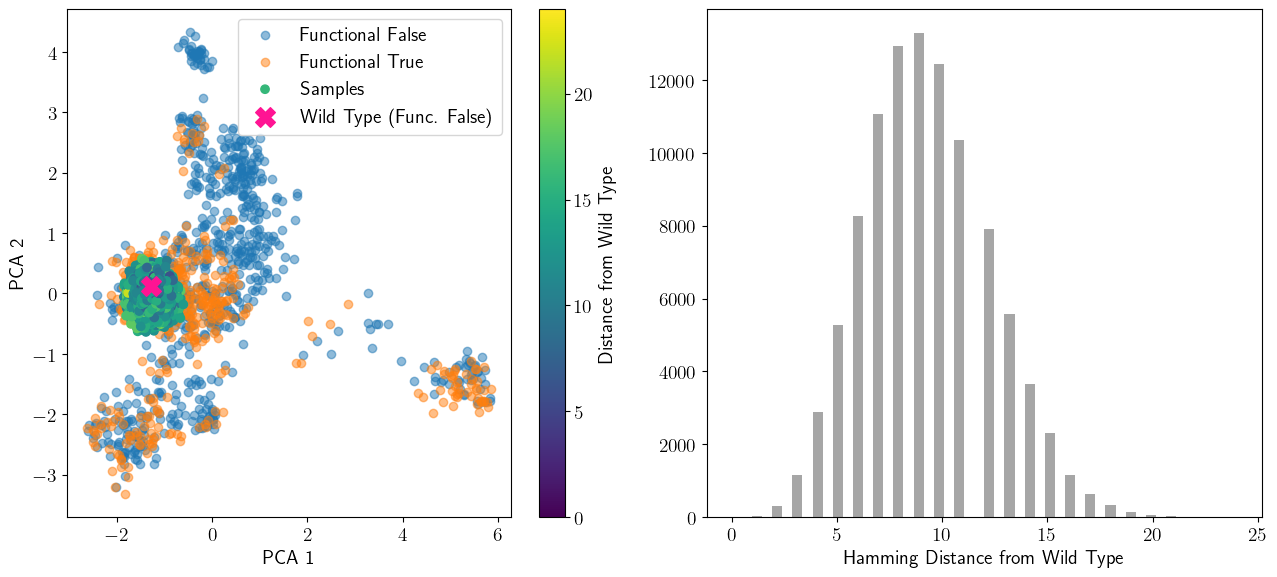

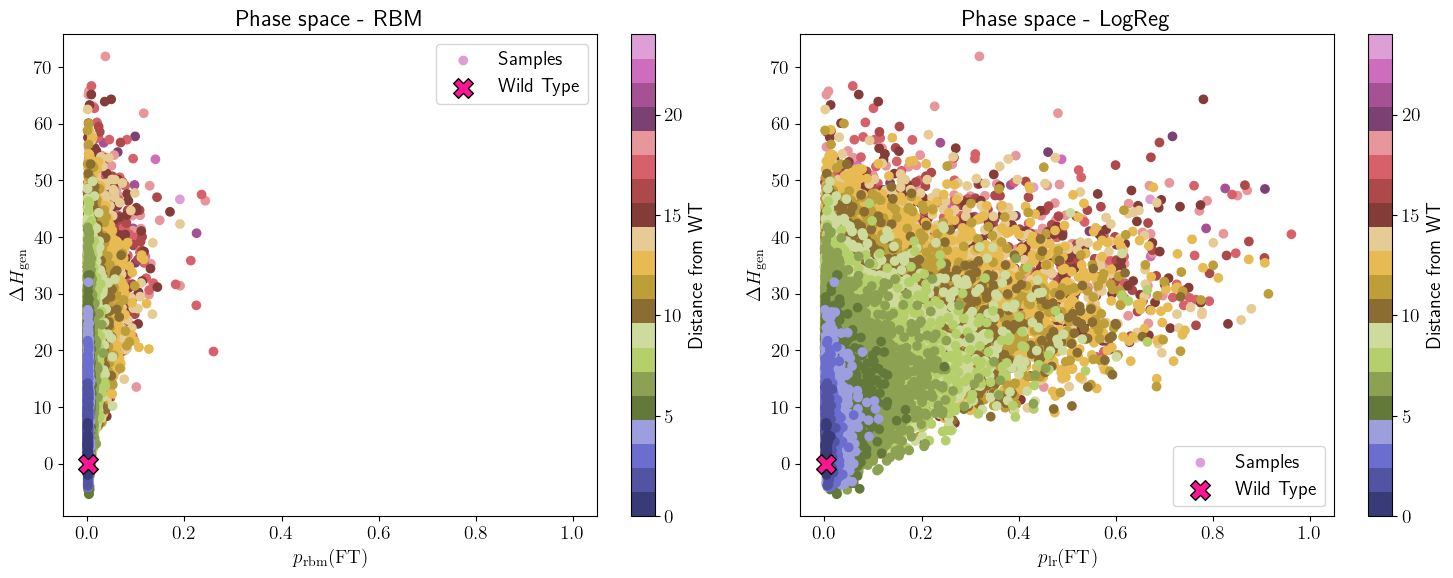

In [101]:
from adabmDCA.fasta import import_from_fasta

path_fasta = "../generated/CM/Seq_gen_bmDCA_gen_strength1.0_label_strength1.0_is_strength3.0.faa"
_, seqs = import_from_fasta(path_fasta, tokens=tokens)
seqs_oh = torch.nn.functional.one_hot(torch.tensor(seqs), num_classes=len(tokens)).to(device=device, dtype=dtype)

p_lr_fran = get_prob_logreg({"visible": seqs_oh}, target_label_oh)
Hgen_fran, p_rbm_fran = get_energy_contributions(
    rbm=rbm,
    samples={"visible": seqs_oh},
    target_label_oh=target_label_oh
)

Hgen_fran = Hgen_fran.cpu().numpy()
p_rbm_fran = p_rbm_fran.cpu().numpy()

# pca
seqs_pca = pca.transform(seqs_oh.view(len(seqs_oh), -1).cpu().numpy())

# distance from WT
distances_fran = get_distance_from_wt(wild_type, {"visible": seqs_oh}).cpu().numpy()

fig, ax = plt.subplots(1, 2, figsize=(13, 6), dpi=100)
ax[0].scatter(data_proj[functional_false_mask, 0], -data_proj[functional_false_mask, 1], label='Functional False', alpha=0.5)
ax[0].scatter(data_proj[~functional_false_mask, 0], -data_proj[~functional_false_mask, 1], label='Functional True', alpha=0.5)
sc = ax[0].scatter(seqs_pca[:, 0], -seqs_pca[:, 1], c=distances_fran, cmap='viridis', label='Samples')
ax[0].scatter(wt_pca[:, 0], -wt_pca[:, 1], marker="X", s=200, c='deeppink', label='Wild Type (Func. False)')
ax[0].legend()
ax[0].set_xlabel("PCA 1")
ax[0].set_ylabel("PCA 2")
# colorbar
cbar = plt.colorbar(sc, ax=ax[0])
cbar.set_label(r"Distance from Wild Type")

ax[1].hist(distances_fran, bins=50, color='gray', alpha=0.7)
ax[1].set_xlabel("Hamming Distance from Wild Type")

fig.tight_layout();

fig, ax = plt.subplots(1, 2, figsize=(15, 6), dpi=100)

idx = np.argsort(distances_fran)[::-1]
sc0 = ax[0].scatter(p_rbm_fran[idx], Hgen_fran[idx] - Hgen_wt.item(), c=distances_fran[idx], cmap="tab20b", label=f"Samples")
ax[0].set_ylabel(r"$\Delta H_{\mathrm{gen}}$")
ax[0].set_xlabel(r"$p_{\mathrm{rbm}}(\mathrm{FT})$")
ax[0].set_title(f"Phase space - RBM")
ax[0].scatter(p_rbm_wt.item(), 0, marker="X", s=200, c='deeppink', label='Wild Type', edgecolor='black')
ax[0].set_xlim(-0.05, 1.05)
ax[0].legend()

sc1 = ax[1].scatter(p_lr_fran[idx], Hgen_fran[idx] - Hgen_wt.item(), c=distances_fran[idx], cmap="tab20b", label=f"Samples")
ax[1].set_ylabel(r"$\Delta H_{\mathrm{gen}}$")
ax[1].set_xlabel(r"$p_{\mathrm{lr}}(\mathrm{FT})$")
ax[1].set_title(f"Phase space - LogReg")
ax[1].scatter(p_lr_wt.item(), 0, marker="X", s=200, c='deeppink', label='Wild Type', edgecolor='black')
ax[1].set_xlim(-0.05, 1.05)
ax[1].legend()

cbar0 = plt.colorbar(sc0, ax=ax[0])
cbar0.set_label(r"Distance from WT")

cbar1 = plt.colorbar(sc1, ax=ax[1])
cbar1.set_label(r"Distance from WT")

fig.tight_layout()

Text(0, 0.5, '$p_lr(FT)$')

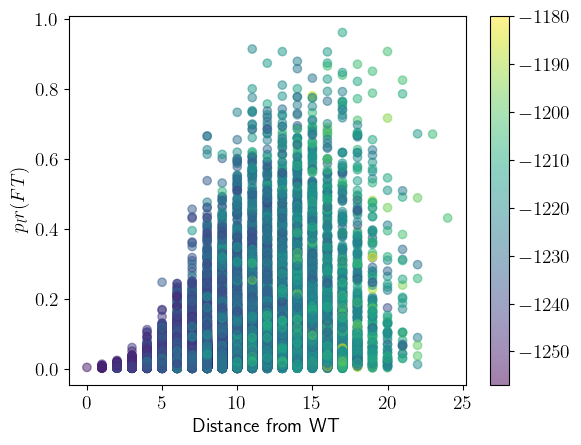

In [100]:
sc = plt.scatter(distances_fran, p_lr_fran, c=Hgen_fran, alpha=0.5);
# colormap
plt.colorbar(sc)
plt.xlabel("Distance from WT")
plt.ylabel(r"$p_lr(FT)$")

### Logo plot patterns

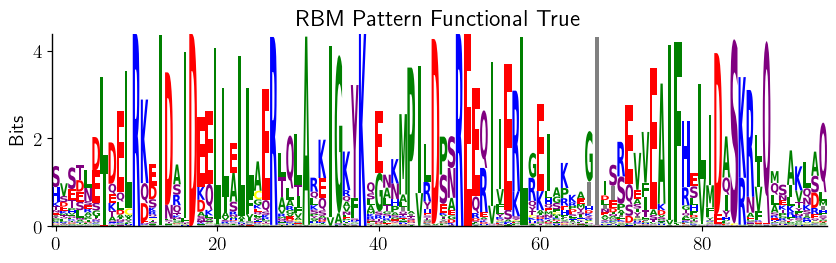

In [10]:
import pandas as pd
import logomaker

def plot_logo(prob, tokens, title=""):
    L, q = prob.shape
    aa_color_scheme = {
        'A': 'green',  # hydrophobic
        'C': 'yellow',
        'D': 'red',    # acidic
        'E': 'red',
        'F': 'green',
        'G': 'green',
        'H': 'blue',   # basic
        'I': 'green',
        'K': 'blue',
        'L': 'green',
        'M': 'green',
        'N': 'purple', # polar
        'P': 'green',
        'Q': 'purple',
        'R': 'blue',
        'S': 'purple',
        'T': 'purple',
        'V': 'green',
        'W': 'green',
        'Y': 'purple',
        '-': 'gray'    # gap
    }
    # Compute information content (bits)
    entropy = -(prob * np.log2(prob + 1e-9)).sum(axis=1)   # H_i
    R = np.log2(q) - entropy                         # R_i
    # Scale each probability by R_i
    IC = prob * R[:, np.newaxis]
    df = pd.DataFrame(IC, columns=list(tokens))
    logo = logomaker.Logo(
        df,
        shade_below=.5,
        fade_below=.5,
        color_scheme=aa_color_scheme,
    )
    logo.style_spines(visible=False)
    logo.style_spines(spines=['left', 'bottom'], visible=True)
    logo.ax.set_ylabel("Bits")
    logo.ax.set_title(title)
    plt.show()

# Should I put the vbias or not?
pattern_rbm = torch.softmax(rbm.get_pattern(dataset.label_to_idx[True]) + rbm.params["vbias"], dim=1)
plot_logo(pattern_rbm.cpu().numpy(), tokens, title="RBM Pattern Functional True")

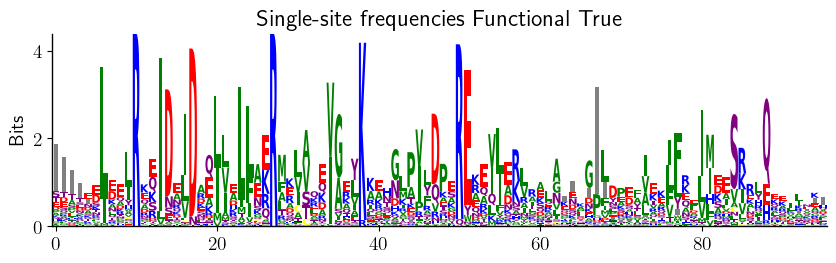

In [13]:
fi_functional_true = get_freq_single_point(
    data=dataset.data_one_hot[dataset.to_label(dataset.labels_one_hot) == True],
    weights=dataset.weights[dataset.to_label(dataset.labels_one_hot) == True]
)

plot_logo(fi_functional_true.cpu().numpy(), tokens, title="Single-site frequencies Functional True")

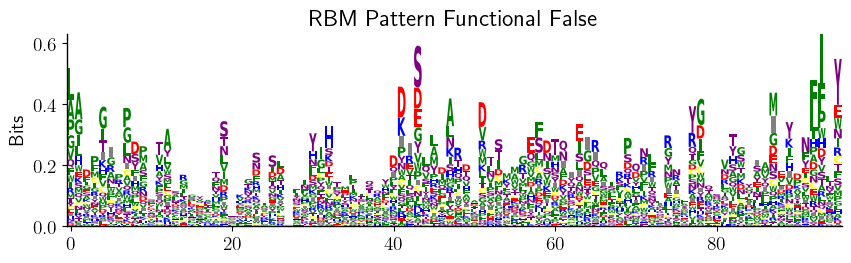

In [14]:
pattern_rbm = torch.softmax(rbm.get_pattern(dataset.label_to_idx[False]), dim=1)
plot_logo(pattern_rbm.cpu().numpy(), tokens, title="RBM Pattern Functional False")

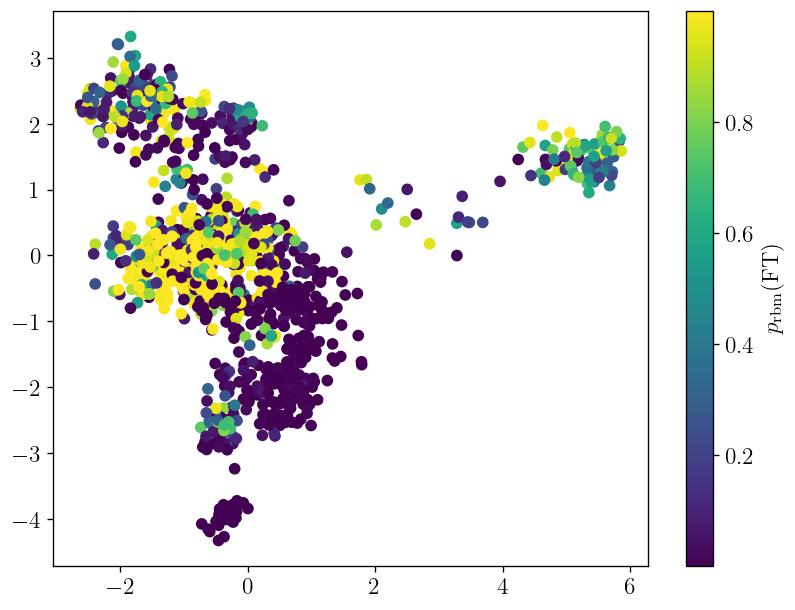

In [52]:
probs_data = rbm.predict_labels(visible=dataset.data_one_hot)[:, dataset.label_to_idx[True]]

fig = plt.figure(figsize=(8,6), dpi=120)
sp = plt.scatter(data_proj[:, 0], data_proj[:, 1], c=probs_data.cpu().numpy(), cmap='viridis', alpha=1.0)
# add colorbar
cbar = plt.colorbar(sp)
cbar.set_label(r"$p_{\mathrm{rbm}}(\mathrm{FT})$")